In [2]:
from sklearn.datasets import make_regression
import numpy as np

In [4]:
X, y = make_regression(n_samples=4, n_features=1, n_informative=1, n_targets=1, noise=80, random_state=13)

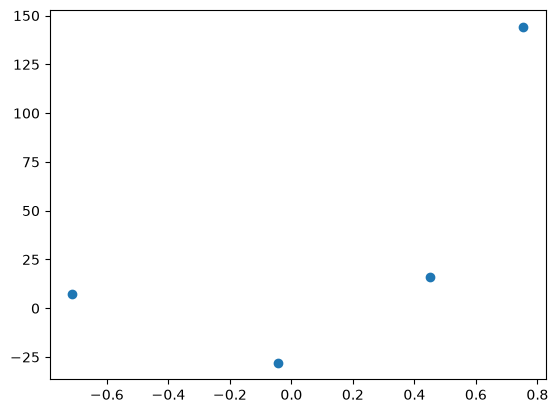

In [5]:
import matplotlib.pyplot as plt
plt.scatter(X,y)

In [6]:
# lets apply OLS
from sklearn.linear_model import LinearRegression

In [7]:
reg = LinearRegression()
reg.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[78.35]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,26.16
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[1.11]


In [8]:
reg.coef_

array([78.35063668])

In [9]:
reg.intercept_

np.float64(26.15963284313262)

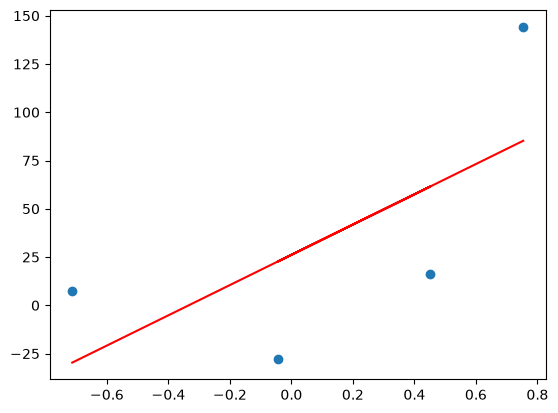

In [10]:
plt.scatter(X,y)
plt.plot(X, reg.predict(X), color='red')

In [13]:
# lets apply Gradient descent assuming slope is constant m=78.35
# and let's assume a starting value for intercept(b) = 0 

y_pred = ((78.35*X)+0).reshape(4) # using formula y=mx+b

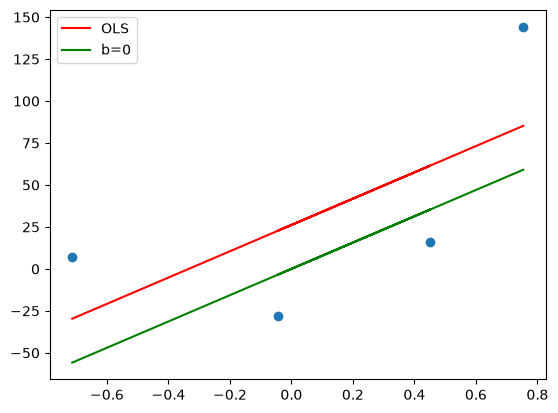

In [15]:
plt.scatter(X, y)
plt.plot(X, reg.predict(X), color='red', label='OLS')
plt.plot(X, y_pred, color='green', label='b=0')
plt.legend()
plt.show()

In [18]:
m = 78.35
b = 0
 # # Flattening with .ravel() ie multidimensional to 1D
loss_slope = -2 * np.sum(y-m*X.ravel()-b) # using formula
loss_slope

np.float64(-209.27763408209216)

In [20]:
# lets take learning rate = 0.1

lr = 0.1
step_size = loss_slope * lr
step_size

np.float64(-20.927763408209216)

In [22]:
# now we find b
b = b - step_size
b

np.float64(20.927763408209216)

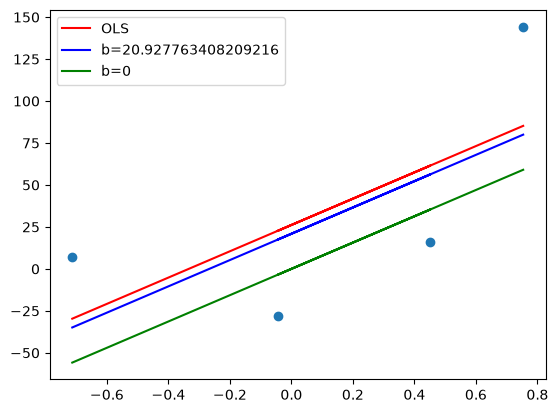

In [23]:
y_pred1 = ((78.35*X)+b).reshape(4) # reshape() changes the shape (dimensions) of an array or tensor without changing its data.

plt.scatter(X, y)
plt.plot(X,reg.predict(X), color='red', label='OLS')
plt.plot(X, y_pred1, color='blue', label='b={}'.format(b))
plt.plot(X,y_pred,color='green', label = 'b=0')
plt.legend()
plt.show()

In [24]:
# iteration 2
loss_slope = -2 * np.sum(y-m*X.ravel()- b)
loss_slope

np.float64(-41.85552681641845)

In [25]:
step_size = loss_slope * lr
step_size

np.float64(-4.185552681641845)

In [26]:
b = b - step_size
b

np.float64(25.11331608985106)

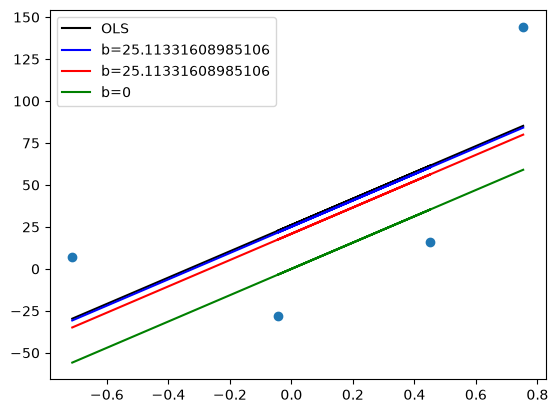

In [32]:
y_pred2 = ((78.35*X+b).reshape(4))

plt.scatter(X,y)
plt.plot(X, reg.predict(X), color ='black', label ='OLS')
plt.plot(X, y_pred2, color='blue', label='b={}'.format(b))
plt.plot(X, y_pred1, color='red', label='b={}'.format(b))
plt.plot(X,y_pred, color='green', label='b=0')
plt.legend()
plt.show()

In [33]:
# iteration 3
loss_slope = -2 * np.sum(y-m*X.ravel()-b)
loss_slope

np.float64(-8.37110536328369)

In [35]:
step_size = loss_slope * lr
step_size

np.float64(-0.837110536328369)

In [36]:
b = b-step_size
b

np.float64(25.95042662617943)

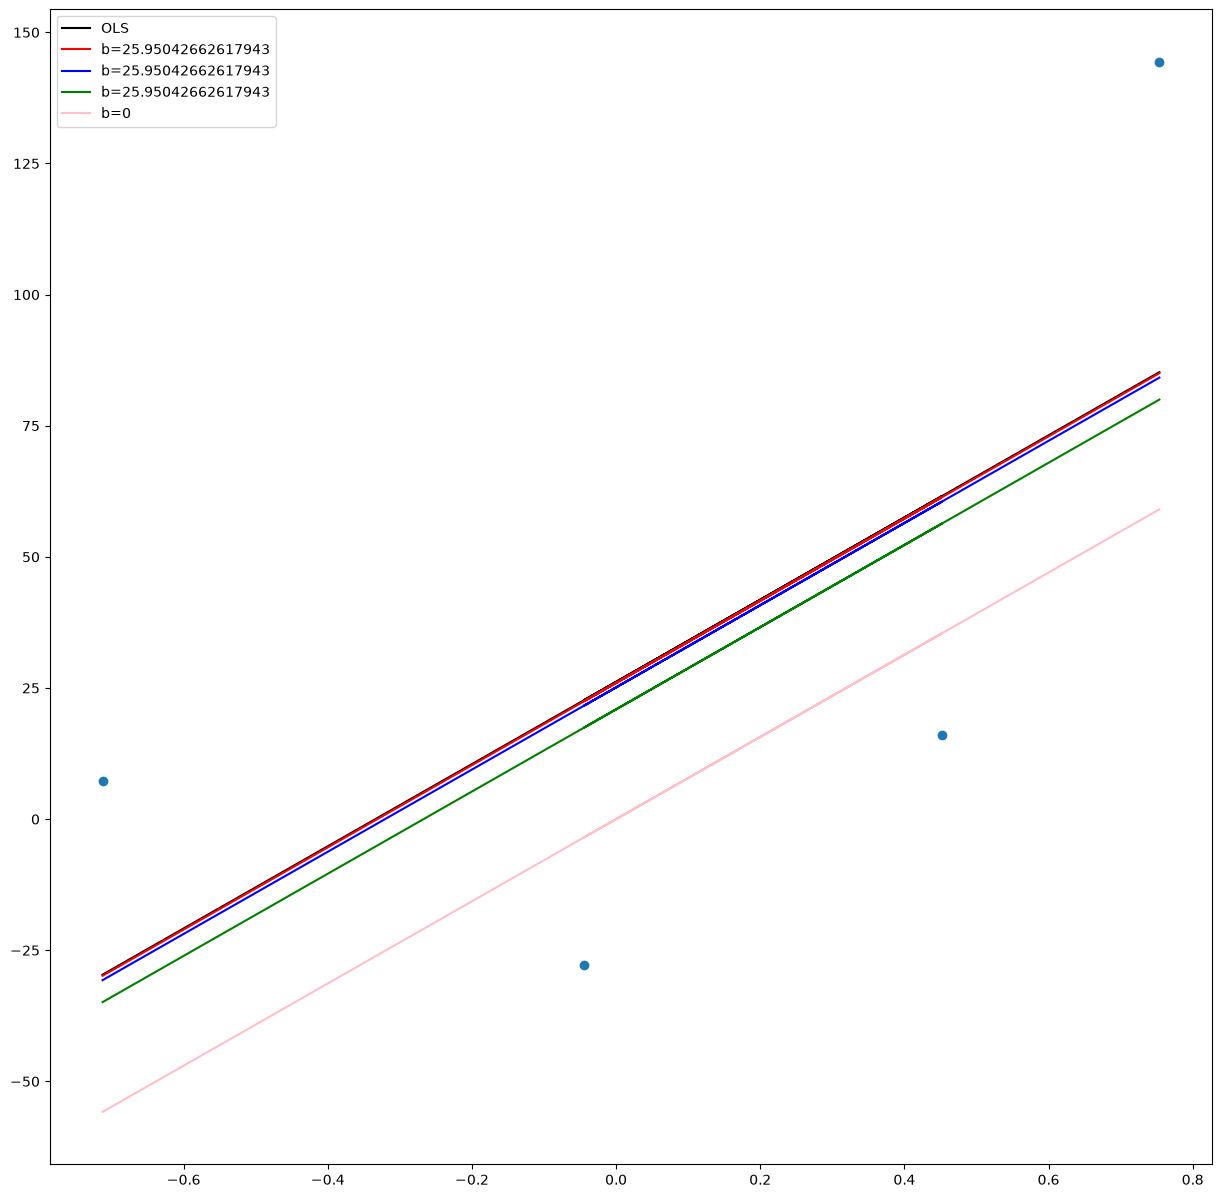

In [40]:
y_pred3 = ((78.35*X) +b ).reshape(4)

plt.figure(figsize=(15,15))
plt.scatter(X,y)
plt.plot(X,reg.predict(X), color = 'black', label='OLS')
plt.plot(X, y_pred3, color = 'red', label= 'b={}'.format(b))
plt.plot(X, y_pred2, color ='blue', label='b={}'.format(b))
plt.plot(X, y_pred1, color = 'green', label='b={}'.format(b))
plt.plot(X, y_pred, color = 'pink', label='b=0')
plt.legend()

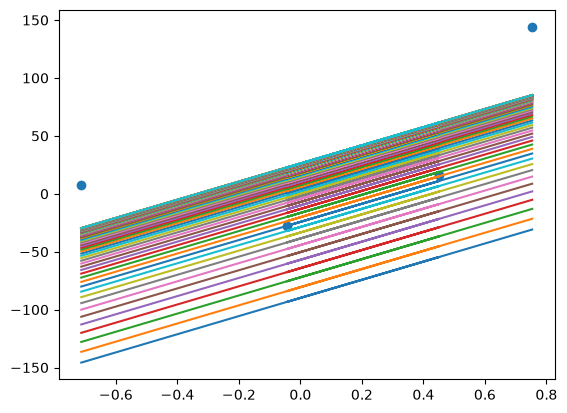

In [44]:
#  in another way in loop
b = -100
m = 78.35
lr = 0.01

epochs = 100

for i in range(epochs):
    loss_slope = -2 * np.sum(y - m*X.ravel()-b)
    b = b - (lr*loss_slope)

    y_pred = m*X+b
    plt.plot(X, y_pred)

plt.scatter(X,y)